In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency

## **EXERCICE 1**

In [2]:
path='https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-SkillsNetwork/labs/Data%20files/automobileEDA.csv'
df = pd.read_csv(path)
df.head()

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


In [5]:
df.dtypes

symboling              int64
normalized-losses      int64
make                     str
aspiration               str
num-of-doors             str
body-style               str
drive-wheels             str
engine-location          str
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type              str
num-of-cylinders         str
engine-size            int64
fuel-system              str
bore                 float64
stroke               float64
compression-ratio    float64
horsepower           float64
peak-rpm             float64
city-mpg               int64
highway-mpg            int64
price                float64
city-L/100km         float64
horsepower-binned        str
diesel                 int64
gas                    int64
dtype: object

In [21]:
corr_matrix=df[['bore','stroke','compression-ratio','horsepower']].corr(method='pearson')
corr_matrix

,bore,stroke,compression-ratio,horsepower
bore,1.000000,-0.055390,0.001263,0.566936
stroke,-0.055390,1.000000,0.187923,0.098462
compression-ratio,0.001263,0.187923,1.000000,-0.214514
horsepower,0.566936,0.098462,-0.214514,1.000000


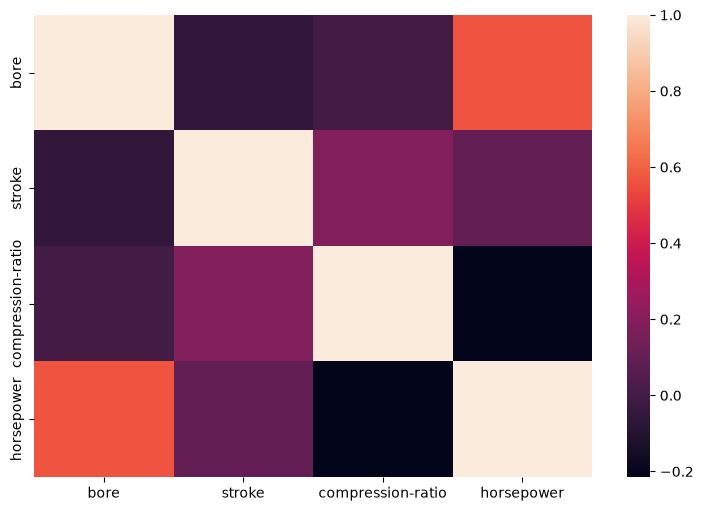

In [22]:
plt.figure(figsize=(9,6))
sns.heatmap(corr_matrix)
plt.show()

(0.0, 53497.5247115755)

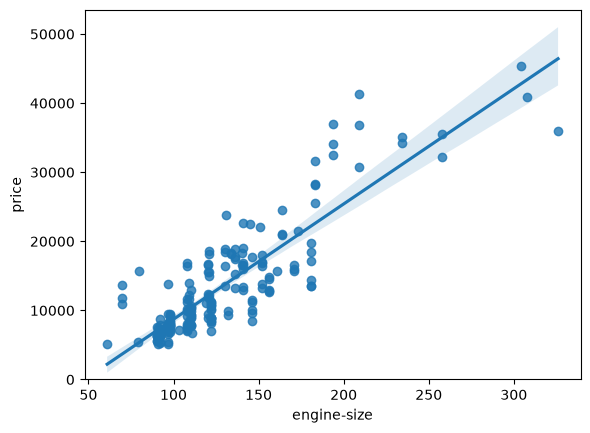

In [24]:
sns.regplot(x="engine-size", y="price", data=df)
plt.ylim(0,)

In [25]:
df[["engine-size", "price"]].corr(method='pearson')

,engine-size,price
engine-size,1.000000,0.872335
price,0.872335,1.000000


(0.0, 48168.08012399183)

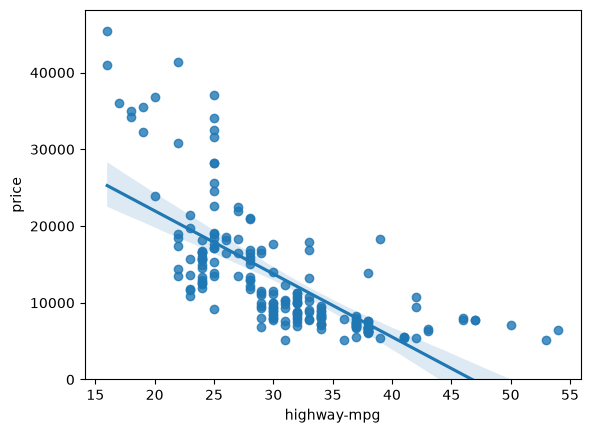

In [27]:
sns.regplot(x="highway-mpg", y="price", data=df)
plt.ylim(0,)

In [28]:
df[["highway-mpg", "price"]].corr(method='pearson')

,highway-mpg,price
highway-mpg,1.000000,-0.704692
price,-0.704692,1.000000


(0.0, 47414.1)

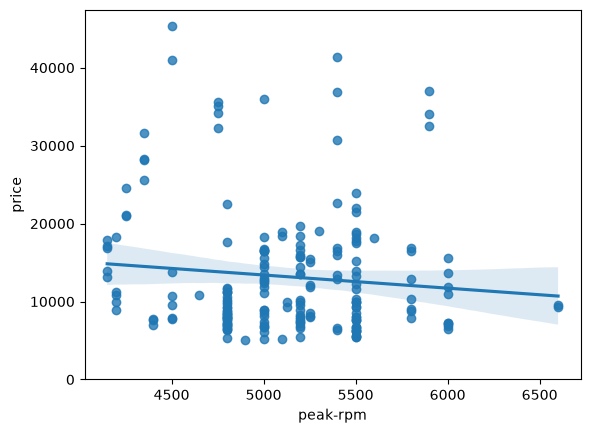

In [30]:
sns.regplot(x="peak-rpm", y="price", data=df)
plt.ylim(0,)

In [31]:
df[["peak-rpm", "price"]].corr(method='pearson')

,peak-rpm,price
peak-rpm,1.000000,-0.101616
price,-0.101616,1.000000


(0.0, 47414.1)

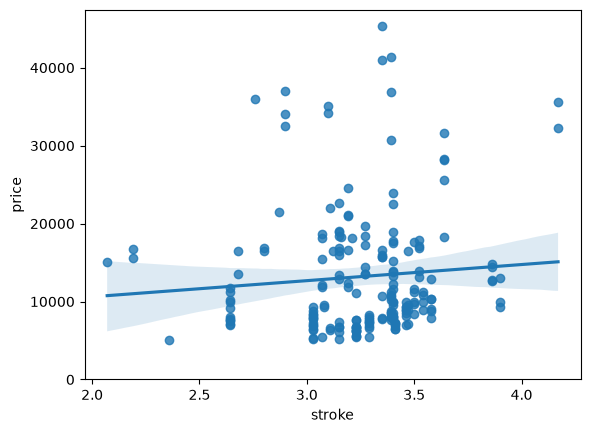

In [32]:
sns.regplot(x="stroke", y="price", data=df)
plt.ylim(0,)

In [33]:
df[["stroke", "price"]].corr(method='pearson')

,stroke,price
stroke,1.00000,0.08231
price,0.08231,1.00000


(0.0, 47414.1)

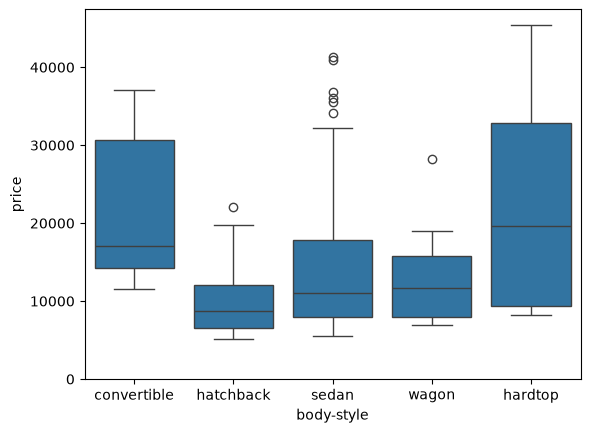

In [35]:
sns.boxplot(x="body-style", y="price", data=df)
plt.ylim(0,)

(0.0, 47414.1)

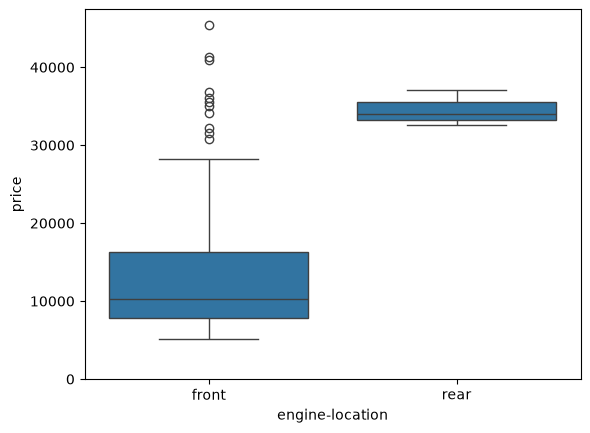

In [36]:
sns.boxplot(x="engine-location", y="price", data=df)
plt.ylim(0,)

(0.0, 47414.1)

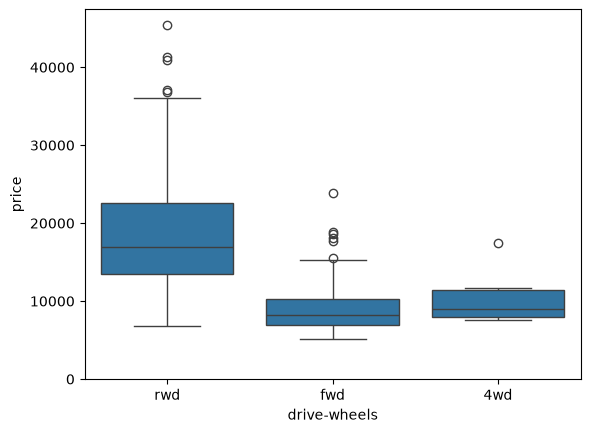

In [37]:
sns.boxplot(x="drive-wheels", y="price", data=df)
plt.ylim(0,)

In [39]:
df.describe(include="all")

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
count,201.000000,201.00000,201,201,201,201,201,201,201.000000,201.000000,...,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,200,201.000000,201.000000
unique,NaN,NaN,22,2,2,5,3,2,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,NaN
top,NaN,NaN,toyota,std,four,sedan,fwd,front,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Low,NaN,NaN
freq,NaN,NaN,32,165,115,94,118,198,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,115,NaN,NaN
mean,0.840796,122.00000,NaN,NaN,NaN,NaN,NaN,NaN,98.797015,0.837102,...,10.164279,103.405534,5117.665368,25.179104,30.686567,13207.129353,9.944145,NaN,0.099502,0.900498
std,1.254802,31.99625,NaN,NaN,NaN,NaN,NaN,NaN,6.066366,0.059213,...,4.004965,37.365700,478.113805,6.423220,6.815150,7947.066342,2.534599,NaN,0.300083,0.300083
min,-2.000000,65.00000,NaN,NaN,NaN,NaN,NaN,NaN,86.600000,0.678039,...,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000,4.795918,NaN,0.000000,0.000000
25%,0.000000,101.00000,NaN,NaN,NaN,NaN,NaN,NaN,94.500000,0.801538,...,8.600000,70.000000,4800.000000,19.000000,25.000000,7775.000000,7.833333,NaN,0.000000,1.000000
50%,1.000000,122.00000,NaN,NaN,NaN,NaN,NaN,NaN,97.000000,0.832292,...,9.000000,95.000000,5125.369458,24.000000,30.000000,10295.000000,9.791667,NaN,0.000000,1.000000
75%,2.000000,137.00000,NaN,NaN,NaN,NaN,NaN,NaN,102.400000,0.881788,...,9.400000,116.000000,5500.000000,30.000000,34.000000,16500.000000,12.368421,NaN,0.000000,1.000000


In [46]:
df['drive-wheels'].value_counts()
df['drive-wheels'].value_counts().to_frame()

,count
drive-wheels,
fwd,118
rwd,75
4wd,8


In [51]:
df_count=df['engine-location'].value_counts().to_frame()
df_count.rename(columns={'engine-location' : 'value_count'}, inplace=True)
df_count.index.name='engine-location'
df_count

,count
engine-location,
front,198
rear,3


In [53]:
df["drive-wheels"].unique()

<StringArray>
['rwd', 'fwd', '4wd']
Length: 3, dtype: str

In [74]:
df_group = df[['drive-wheels','body-style','price']]
df_group_one = df_group.groupby(['drive-wheels'], as_index=False)['price'].mean()
df_group_one

,drive-wheels,price
0,4wd,10241.000000
1,fwd,9244.779661
2,rwd,19757.613333


In [75]:
df_group_one = df_group.groupby(['body-style'], as_index=False)['price'].mean()
df_group_one

,body-style,price
0,convertible,21890.500000
1,hardtop,22208.500000
2,hatchback,9957.441176
3,sedan,14459.755319
4,wagon,12371.960000


In [79]:
group_test = df_group.groupby(['drive-wheels','body-style'],as_index=False)['price'].mean()
group_test.sort_values(by=['price'],ascending=False)

,drive-wheels,body-style,price
9,rwd,hardtop,24202.714286
8,rwd,convertible,23949.600000
11,rwd,sedan,21711.833333
12,rwd,wagon,16994.222222
10,rwd,hatchback,14337.777778
1,4wd,sedan,12647.333333
3,fwd,convertible,11595.000000
7,fwd,wagon,9997.333333
6,fwd,sedan,9811.800000
2,4wd,wagon,9095.750000


In [82]:
group_pivot=group_test.pivot(index="drive-wheels", columns="body-style")

In [83]:
group_pivot.fillna(0)

price                                            \
body-style   convertible       hardtop     hatchback         sedan   
drive-wheels                                                         
4wd                  0.0      0.000000   7603.000000  12647.333333   
fwd              11595.0   8249.000000   8396.387755   9811.800000   
rwd              23949.6  24202.714286  14337.777778  21711.833333   

                            
body-style           wagon  
drive-wheels                
4wd            9095.750000  
fwd            9997.333333  
rwd           16994.222222

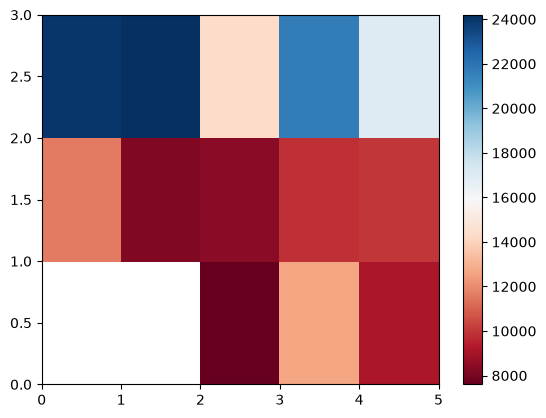

In [85]:
plt.pcolor(group_pivot, cmap='RdBu')
plt.colorbar()
plt.show()

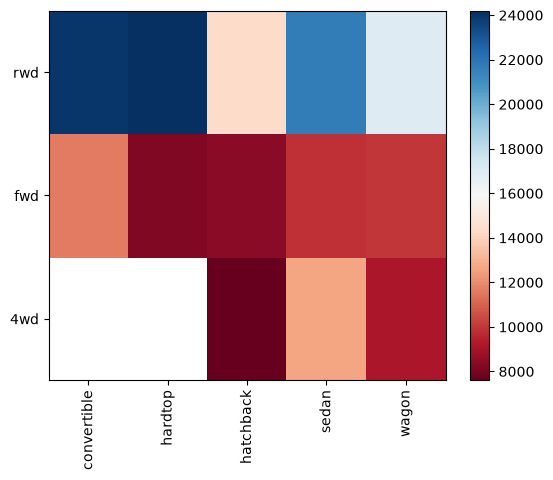

In [87]:
fig, ax = plt.subplots()
im = ax.pcolor(group_pivot, cmap='RdBu')

#label names
row_labels = group_pivot.columns.levels[1]
col_labels = group_pivot.index

#move ticks and labels to the center
ax.set_xticks(np.arange(group_pivot.shape[1]) + 0.5, minor=False)
ax.set_yticks(np.arange(group_pivot.shape[0]) + 0.5, minor=False)

#insert labels
ax.set_xticklabels(row_labels, minor=False)
ax.set_yticklabels(col_labels, minor=False)

#rotate label if too long
plt.xticks(rotation=90)

fig.colorbar(im)
plt.show()

## **CORRELATION AND CAUSATION**

In [105]:
corr, pvalue=stats.pearsonr(df['price'], df['wheel-base'])
print("la correlation est ",corr, " et la pvalue est " , pvalue.round(3))

la correlation est  0.584641822265508  et la pvalue est  0.0


In [106]:
corr, pvalue=stats.pearsonr(df['price'], df['horsepower'])
print("la correlation est ",corr, " et la pvalue est " , pvalue.round(3))

la correlation est  0.8095745670036562  et la pvalue est  0.0


In [108]:
corr, pvalue=stats.pearsonr(df['price'], df['length'])
print("la correlation est ",corr, " et la pvalue est " , pvalue.round(3))

la correlation est  0.6906283804483639  et la pvalue est  0.0


In [112]:
corr, pvalue=stats.pearsonr(df['price'], df['curb-weight'])
print("la correlation est ",corr, " et la pvalue est " , pvalue.round(3))

la correlation est  0.8344145257702844  et la pvalue est  0.0


In [113]:
corr, pvalue=stats.pearsonr(df['price'], df['engine-size'])
print("la correlation est ",corr, " et la pvalue est " , pvalue.round(3))

la correlation est  0.8723351674455184  et la pvalue est  0.0


In [114]:
corr, pvalue=stats.pearsonr(df['price'], df['bore'])
print("la correlation est ",corr, " et la pvalue est " , pvalue.round(3))

la correlation est  0.5431553832626603  et la pvalue est  0.0


In [115]:
corr, pvalue=stats.pearsonr(df['price'], df['city-mpg'])
print("la correlation est ",corr, " et la pvalue est " , pvalue.round(3))

la correlation est  -0.686571006784468  et la pvalue est  0.0


In [116]:
corr, pvalue=stats.pearsonr(df['price'], df['highway-mpg'])
print("la correlation est ",corr, " et la pvalue est " , pvalue.round(3))

la correlation est  -0.7046922650589531  et la pvalue est  0.0


## **CONCLUSION**

<p>We now have a better idea of what our data looks like and which variables are important to take into account when predicting the car price. We have narrowed it down to the following variables:</p>

Continuous numerical variables:
<ul>
    <li>Length</li>
    <li>Width</li>
    <li>Curb-weight</li>
    <li>Engine-size</li>
    <li>Horsepower</li>
    <li>City-mpg</li>
    <li>Highway-mpg</li>
    <li>Wheel-base</li>
    <li>Bore</li>
</ul>
    
Categorical variables:
<ul>
    <li>Drive-wheels</li>
</ul>

<p>As we now move into building machine learning models to automate our analysis, feeding the model with variables that meaningfully affect our target variable will improve our model's prediction performance.</p>


## **EXCERCICE 2**

In [133]:
filepath="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-Coursera/laptop_pricing_dataset_mod2.csv"
df = pd.read_csv(filepath, header=None)

In [139]:
headers=["?","??","Manufacturer", "Category", "GPU", "OS", "CPU_core","Screen_Size_inch", "CPU_frequency", "RAM_GB", "Storage_GB_SSD", "Weight_pounds", "Price", "Price-binned", "Screen-Full_HD","Screen-IPS_panel"]
df.columns= headers
df.head(5)

,?,??,Manufacturer,Category,GPU,OS,CPU_core,Screen_Size_inch,CPU_frequency,RAM_GB,Storage_GB_SSD,Weight_pounds,Price,Price-binned,Screen-Full_HD,Screen-IPS_panel
0,0,0,Acer,4,2,1,5,14.0,0.551724,8,256,3.52800,978,Low,0,1
1,1,1,Dell,3,1,1,3,15.6,0.689655,4,256,4.85100,634,Low,1,0
2,2,2,Dell,3,1,1,7,15.6,0.931034,8,256,4.85100,946,Low,1,0
3,3,3,Dell,4,2,1,5,13.3,0.551724,8,128,2.69010,1244,Low,0,1
4,4,4,HP,4,2,1,7,15.6,0.620690,8,256,4.21155,837,Low,1,0


In [155]:
df["CPU_frequency"].dtypes

dtype('float64')

(0.0, 3974.15)

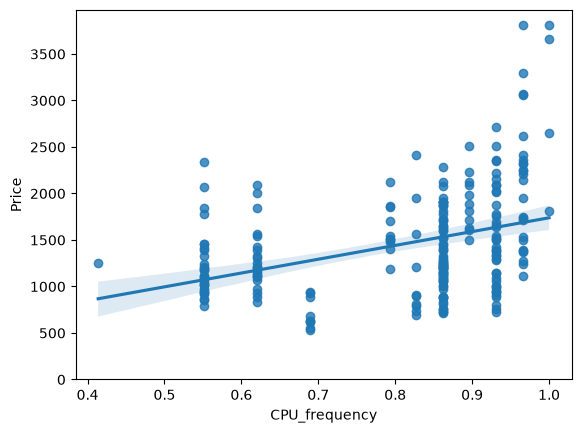

In [151]:
sns.regplot(x='CPU_frequency', y="Price", data=df)
plt.ylim(0,)

In [158]:
corr, pvalue= stats.pearsonr(df['CPU_frequency'], df['Price'])
print("Le correlation est ", corr , " et la pvalue est ",pvalue.round(4) )

Le correlation est  0.36666555892588604  et la pvalue est  0.0


(0.0, 3974.15)

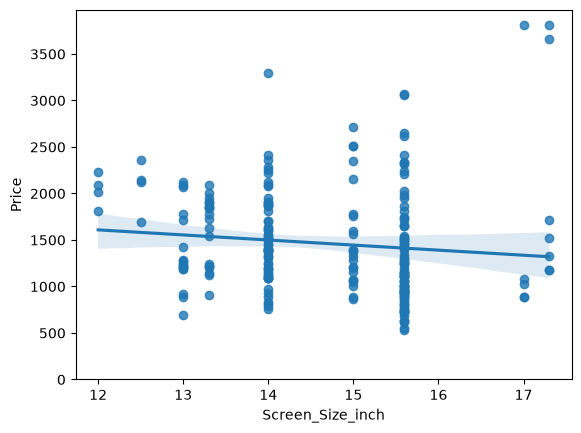

In [152]:
sns.regplot(x='Screen_Size_inch', y="Price", data=df)
plt.ylim(0,)

In [160]:
corr, pvalue= stats.pearsonr(df['Screen_Size_inch'], df['Price'])
print("Le correlation est ", corr , " et la pvalue est ",pvalue.round(4) )

Le correlation est  -0.11064420817118266  et la pvalue est  0.0885


(0.0, 3974.15)

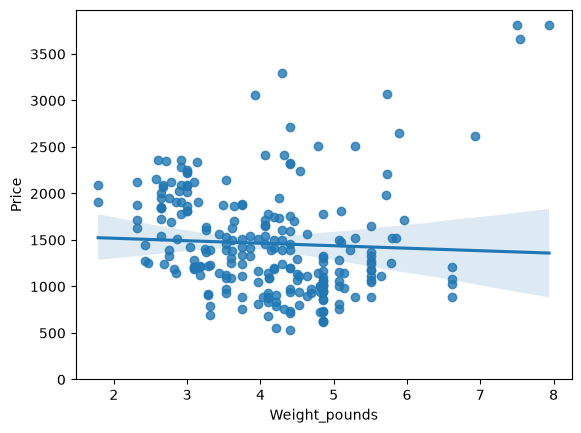

In [161]:
sns.regplot(x="Weight_pounds", y="Price", data=df)
plt.ylim(0,)

In [162]:
corr, pvalue= stats.pearsonr(df['Weight_pounds'], df['Price'])
print("Le correlation est ", corr , " et la pvalue est ",pvalue.round(4) )

Le correlation est  -0.05031225837751549  et la pvalue est  0.4398


<Axes: xlabel='Category', ylabel='Price'>

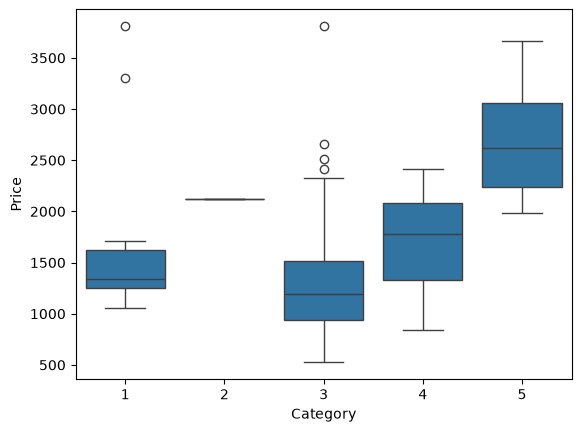

In [163]:
sns.boxplot(x="Category", y="Price", data=df)

<Axes: xlabel='GPU', ylabel='Price'>

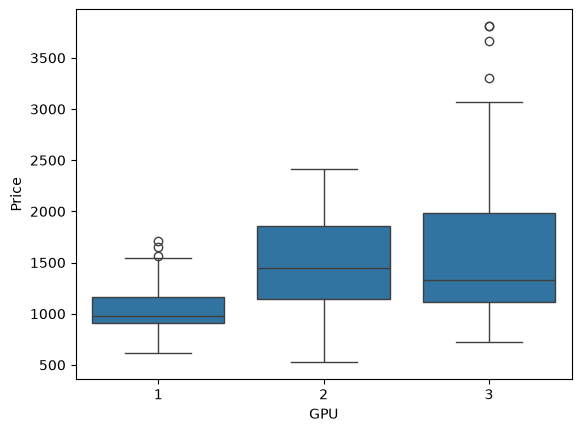

In [164]:
sns.boxplot(x="GPU", y="Price", data=df)

<Axes: xlabel='OS', ylabel='Price'>

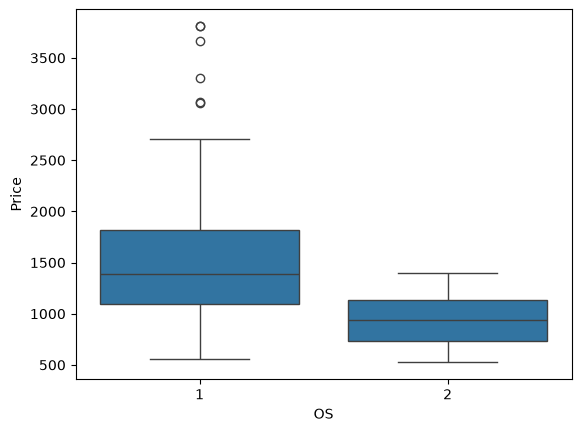

In [165]:
sns.boxplot(x="OS", y="Price", data=df)

<Axes: xlabel='CPU_core', ylabel='Price'>

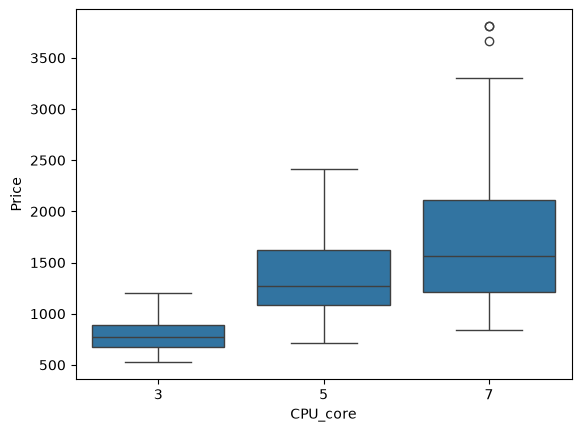

In [166]:
sns.boxplot(x="CPU_core", y="Price", data=df)

<Axes: xlabel='RAM_GB', ylabel='Price'>

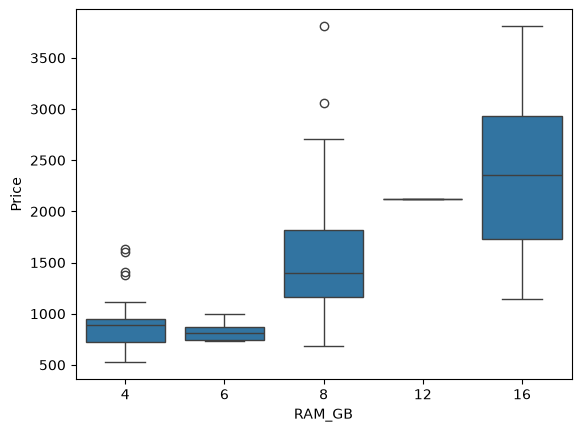

In [167]:
sns.boxplot(x="RAM_GB", y="Price", data=df)

<Axes: xlabel='Storage_GB_SSD', ylabel='Price'>

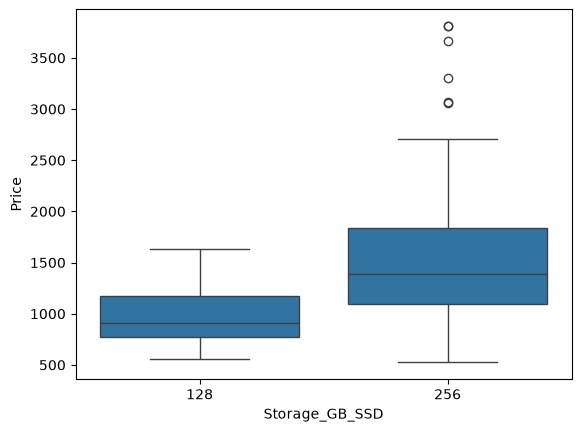

In [168]:
sns.boxplot(x="Storage_GB_SSD", y="Price", data=df)

<Axes: xlabel='Manufacturer', ylabel='Price'>

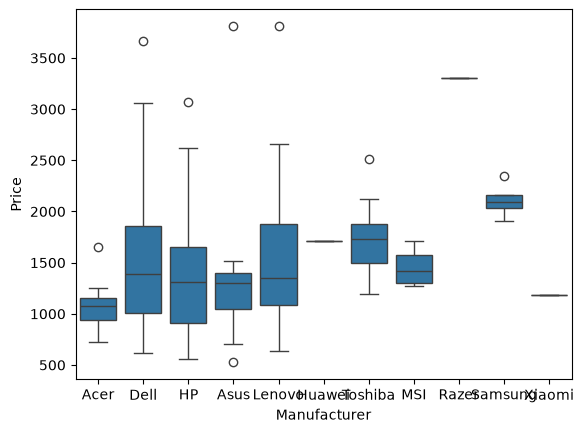

In [170]:
sns.boxplot(x="Manufacturer", y="Price", data=df)

In [169]:
df.describe(include="all")

,?,??,Manufacturer,Category,GPU,OS,CPU_core,Screen_Size_inch,CPU_frequency,RAM_GB,Storage_GB_SSD,Weight_pounds,Price,Price-binned,Screen-Full_HD,Screen-IPS_panel
count,238.000000,238.000000,238,238.000000,238.000000,238.000000,238.000000,238.000000,238.000000,238.000000,238.000000,238.000000,238.000000,238,238.000000,238.000000
unique,NaN,NaN,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,NaN
top,NaN,NaN,Dell,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Low,NaN,NaN
freq,NaN,NaN,71,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,160,NaN,NaN
mean,118.500000,118.500000,NaN,3.205882,2.151261,1.058824,5.630252,14.688655,0.813822,7.882353,245.781513,4.106221,1462.344538,NaN,0.676471,0.323529
std,68.848868,68.848868,NaN,0.776533,0.638282,0.235790,1.241787,1.166045,0.141860,2.482603,34.765316,1.078442,574.607699,NaN,0.468809,0.468809
min,0.000000,0.000000,NaN,1.000000,1.000000,1.000000,3.000000,12.000000,0.413793,4.000000,128.000000,1.786050,527.000000,NaN,0.000000,0.000000
25%,59.250000,59.250000,NaN,3.000000,2.000000,1.000000,5.000000,14.000000,0.689655,8.000000,256.000000,3.246863,1066.500000,NaN,0.000000,0.000000
50%,118.500000,118.500000,NaN,3.000000,2.000000,1.000000,5.000000,15.000000,0.862069,8.000000,256.000000,4.106221,1333.000000,NaN,1.000000,0.000000
75%,177.750000,177.750000,NaN,4.000000,3.000000,1.000000,7.000000,15.600000,0.931034,8.000000,256.000000,4.851000,1777.000000,NaN,1.000000,1.000000


In [171]:
df_group=df[["GPU","CPU_core","Price"]]

In [183]:
df_grouped=df_group.groupby(['GPU','CPU_core'], as_index=False)['Price'].mean()
df_pivot= df_grouped.pivot(index="GPU",columns="CPU_core")
df_pivot

Price                          
CPU_core           3            5            7
GPU                                           
1         769.250000   998.500000  1167.941176
2         785.076923  1462.197674  1744.621622
3         784.000000  1220.680000  1945.097561

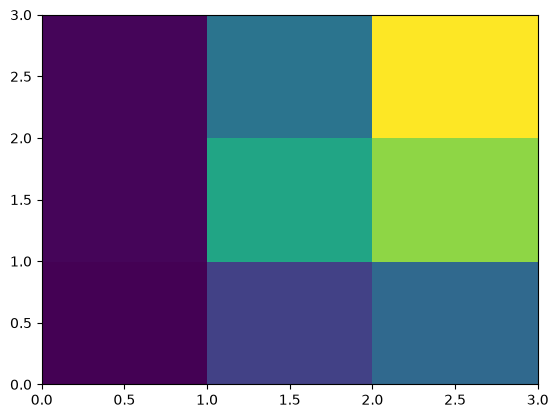

In [185]:
plt.pcolor(df_pivot)

In [187]:
for param in ['RAM_GB','CPU_frequency','Storage_GB_SSD','Screen_Size_inch','Weight_pounds','CPU_core','OS','GPU','Category']:
    pearson_coef, p_value = stats.pearsonr(df[param], df['Price'])
    print(param)
    print("The Pearson Correlation Coefficient for ",param," is", pearson_coef, " with a P-value of P =", p_value.round(4))

RAM_GB
The Pearson Correlation Coefficient for  RAM_GB  is 0.5492972971857844  with a P-value of P = 0.0
CPU_frequency
The Pearson Correlation Coefficient for  CPU_frequency  is 0.36666555892588604  with a P-value of P = 0.0
Storage_GB_SSD
The Pearson Correlation Coefficient for  Storage_GB_SSD  is 0.243420755218103  with a P-value of P = 0.0001
Screen_Size_inch
The Pearson Correlation Coefficient for  Screen_Size_inch  is -0.11064420817118266  with a P-value of P = 0.0885
Weight_pounds
The Pearson Correlation Coefficient for  Weight_pounds  is -0.05031225837751549  with a P-value of P = 0.4398
CPU_core
The Pearson Correlation Coefficient for  CPU_core  is 0.4593977773355115  with a P-value of P = 0.0
OS
The Pearson Correlation Coefficient for  OS  is -0.22172980114827384  with a P-value of P = 0.0006
GPU
The Pearson Correlation Coefficient for  GPU  is 0.2882981988881427  with a P-value of P = 0.0
Category
The Pearson Correlation Coefficient for  Category  is 0.28624275581264125  with

In [188]:
df["RAM_GB"].dtypes

dtype('int64')